<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Lab_7_Kmeans_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 7**

**Aim - To implement K-Means Clustering using sample dataset**

**Peeyush Agarwal 2427010184 AIM3130**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
df = pd.read_csv('city_lifestyle_dataset.csv')

In [ ]:
df.head()

,city_name,country,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,Old Vista,Europe,2775,3850,86.4,1310,43,52.0,8.5,23.8
1,Beachport,Europe,3861,3700,78.1,1330,42,62.8,8.1,33.1
2,Valleyborough,Europe,2562,4310,80.1,1330,39,73.2,8.5,40.2
3,City,Europe,3192,3970,81.2,1480,60,49.2,8.5,43.6
4,Falls,Europe,3496,4320,100.0,1510,64,93.7,8.5,42.5


In [ ]:
# Display the number of rows and columns
print("Shape of dataset:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns)

# Display data types and non-null values
print("\nDataset information:")
df.info()

Shape of dataset: (300, 10)

Column names:
Index(['city_name', 'country', 'population_density', 'avg_income',
       'internet_penetration', 'avg_rent', 'air_quality_index',
       'public_transport_score', 'happiness_score', 'green_space_ratio'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_name               300 non-null    object 
 1   country                 300 non-null    object 
 2   population_density      300 non-null    int64  
 3   avg_income              300 non-null    int64  
 4   internet_penetration    300 non-null    float64
 5   avg_rent                300 non-null    int64  
 6   air_quality_index       300 non-null    int64  
 7   public_transport_score  300 non-null    float64
 8   happiness_score         300 non-null    float64
 9   green_space_rat

In [ ]:
# Check the number of missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check the number of duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values:
city_name                 0
country                   0
population_density        0
avg_income                0
internet_penetration      0
avg_rent                  0
air_quality_index         0
public_transport_score    0
happiness_score           0
green_space_ratio         0
dtype: int64

Number of duplicate rows: 0


In [ ]:
# Select numerical features for K-Means clustering
features = [
    'population_density',
    'avg_income',
    'internet_penetration',
    'avg_rent',
    'air_quality_index',
    'public_transport_score',
    'happiness_score',
    'green_space_ratio'
]

# Create a separate DataFrame containing only the selected features
X = df[features]

# Display the first 5 rows
X.head()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,2775,3850,86.4,1310,43,52.0,8.5,23.8
1,3861,3700,78.1,1330,42,62.8,8.1,33.1
2,2562,4310,80.1,1330,39,73.2,8.5,40.2
3,3192,3970,81.2,1480,60,49.2,8.5,43.6
4,3496,4320,100.0,1510,64,93.7,8.5,42.5


In [ ]:
# Display statistical summary of the selected features
X.describe()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,3944.843333,2827.200000,74.305333,1002.766667,71.246667,55.717333,6.644000,33.993333
std,2982.566777,1201.163939,17.014492,456.282066,25.344961,14.712549,1.685864,9.434067
min,100.000000,480.000000,34.000000,170.000000,22.000000,15.000000,2.500000,2.000000
25%,1830.000000,1907.500000,64.400000,640.000000,54.000000,46.075000,5.300000,28.225000
50%,3083.500000,2810.000000,75.000000,990.000000,67.500000,54.700000,6.900000,34.700000
75%,4823.750000,3752.500000,87.225000,1332.500000,86.000000,64.200000,8.500000,40.400000
max,14427.000000,5720.000000,100.000000,2430.000000,146.000000,95.000000,8.500000,58.000000


In [ ]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler and transform the selected features
X_scaled = scaler.fit_transform(X)

# Convert the scaled array back into a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=features)

# Display the first 5 scaled rows
X_scaled.head()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,-0.392882,0.852930,0.712033,0.674466,-1.116351,-0.253086,1.102759,-1.082287
1,-0.028158,0.727843,0.223398,0.718372,-1.155872,0.482207,0.865095,-0.094850
2,-0.464417,1.236532,0.341141,0.718372,-1.274437,1.190268,1.102759,0.658999
3,-0.252836,0.953000,0.405900,1.047665,-0.444485,-0.443718,1.102759,1.019997
4,-0.150740,1.244871,1.512687,1.113524,-0.286399,2.585965,1.102759,0.903203


In [ ]:
# Create the K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the K-Means model on the scaled data
kmeans.fit(X_scaled)

# Get the cluster assigned to each city
clusters = kmeans.labels_

# Add the cluster labels to the original dataset
df['Cluster'] = clusters

# Display the first 5 rows with their cluster assignments
df.head()

,city_name,country,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio,Cluster
0,Old Vista,Europe,2775,3850,86.4,1310,43,52.0,8.5,23.8,2
1,Beachport,Europe,3861,3700,78.1,1330,42,62.8,8.1,33.1,2
2,Valleyborough,Europe,2562,4310,80.1,1330,39,73.2,8.5,40.2,2
3,City,Europe,3192,3970,81.2,1480,60,49.2,8.5,43.6,2
4,Falls,Europe,3496,4320,100.0,1510,64,93.7,8.5,42.5,2


In [ ]:
# Count the number of cities in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

# Display the number of cities in each cluster
print("Number of cities in each cluster:")
print(cluster_counts)# Count the number of cities in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

# Display the number of cities in each cluster
print("Number of cities in each cluster:")
print(cluster_counts)

Number of cities in each cluster:
Cluster
0     44
1     82
2    110
3     64
Name: count, dtype: int64
Number of cities in each cluster:
Cluster
0     44
1     82
2    110
3     64
Name: count, dtype: int64


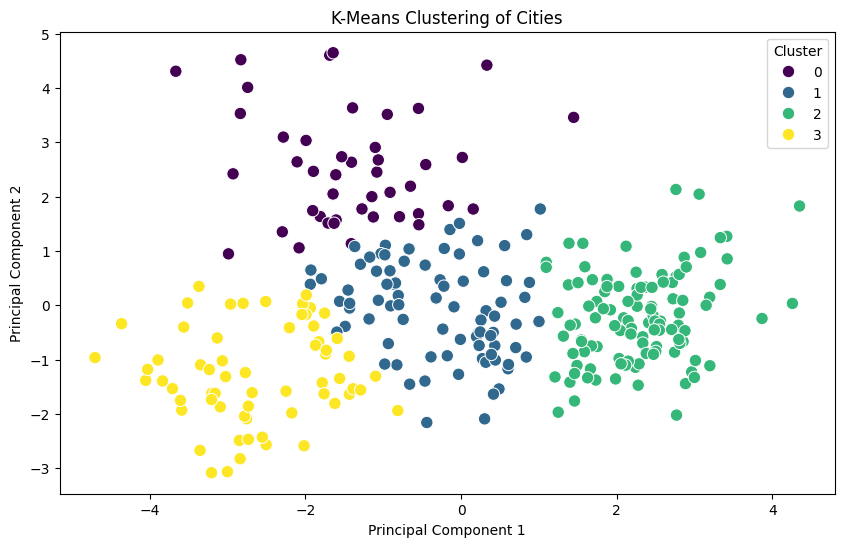

In [ ]:
# Import PCA for reducing the dimensions to 2D for visualization
from sklearn.decomposition import PCA

# Reduce the 8 scaled features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame containing the two principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Add the cluster labels
pca_df['Cluster'] = df['Cluster']

# Plot the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='viridis',
    s=80
)

# Add title and axis labels
plt.title("K-Means Clustering of Cities")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Display legend
plt.legend(title="Cluster")

# Show the plot
plt.show()

In [ ]:
# Calculate the mean value of each feature for every cluster
cluster_summary = df.groupby('Cluster')[features].mean()

# Display the cluster summary
cluster_summary

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
Cluster,,,,,,,,
0,9690.681818,2564.545455,73.390909,887.272727,108.000000,64.354545,5.250000,22.245455
1,4226.280488,2524.268293,73.457317,899.878049,72.975610,54.980488,6.629268,35.037805
2,2160.936364,4083.181818,88.920000,1463.363636,50.372727,62.840000,8.389091,36.743636
3,2700.078125,1237.187500,50.901562,422.343750,79.640625,38.481250,4.621875,36.004688
